# Lane Perception Development — Phase 0.2

Replay saved images through the **real preprocessing module**, retaining frame identity and timing. No camera, Gateway, serial port, lane search or control is started here. The completed preprocessing notebook remains separate and unchanged.

Live `capture_return_estimate` is an approximate monotonic time after `capture_array()` returns, not sensor exposure. Simulated replay time is an explicitly assumed timeline, independent of notebook execution speed.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import deque
import sys
import time
import platform
import matplotlib.pyplot as plt
import cv2

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/utils/frame_packet.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start the notebook from SCRbrain or SCRbrain/notebooks.')
for path in (PROJECT_ROOT, PROJECT_ROOT / 'notebooks'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
from src.algorithms.LaneDetection.utils.preprocessing import PreprocessingMixin
from src.utils.frame_packet import FramePacketOrder, preprocess_frame_packet, LatencyStatistics
from helpers.frame_replay import iter_replay_packets, replay_timing_sample, adapt_replay_packet
print('Replay host:', platform.platform(), sys.version.split()[0])

Replay host: Windows-11-10.0.26200-SP0 3.12.10


## Replay configuration

Use one directory/manifest per real sequence. Paths may be outside this repository; relative paths resolve below PROJECT_ROOT. `IMAGE_DIRECTORY = None` uses five in-memory demo images, creating no files. Re-running simulated replay creates a new session unless an explicit ID is supplied.

Simulated FPS is an assumption, **not the original capture rate**. Recorded mode accepts JSON or JSONL metadata and preserves its session IDs, frame IDs and capture times. Camera calibration is not performed. Optional image adaptation below can prepare non-BFMC images for the fixed camera input shape. Set `EXPECTED_FRAME_SHAPE = None` only for exploratory non-camera-sized images; those do not validate the real camera geometry.

In [2]:
TEST_IMAGE_DIRECTORY = "notebooks/II_test_images_lane_exctraction"  # Relative to PROJECT_ROOT; absolute path or None for demo.
REPLAY_MODE = 'simulated'        # 'simulated' or 'recorded'
RECORDED_METADATA_PATH = None    # JSON/JSONL file for recorded mode
ASSUMED_FPS = 5.0                # Only used in simulated mode; user assumption
REPLAY_SESSION_ID = None         # None generates a fresh simulated-session UUID
MAX_FRAMES = 20                  # None processes the entire chosen sequence
DISPLAY_LIMIT = 20                # Bound notebook figure output
EXPECTED_FRAME_SHAPE = (270, 512, 3)  # Actual camera BGR shape; None explicitly permits other sizes

def replay_path(value):
    if value is None:
        return None
    path = Path(value).expanduser()
    return path if path.is_absolute() else PROJECT_ROOT / path

## Optional Image Adaptation – Non-BFMC Images

Offline testing only. Enable to reuse the existing preprocessing notebook's proportional height resize and centered mean-color padding/cropping, targeting the previous notebook test canvas **650x270**. Optional bottom cropping then uses the same crop → proportional resize → horizontal center-crop sequence. This changes screenshot framing, not production calibration.

Disabled packets pass through untouched. Enabled packets retain their original IDs/timestamps and JPEG-encode only the prepared image for the common processing interface. Only the first original input is shown once as a reference; binary BEV outputs retain the existing DISPLAY_LIMIT. The shared normalizer's 650x270 defaults are temporarily overridden and restored within each call; do not run concurrent notebook normalization in the same kernel during this helper call.

In [3]:
USE_IMAGE_ADAPTATION = True  # Offline screenshot convenience only.
BOTTOM_CROP_ENABLE = False
BOTTOM_CROP_PX = 110
TEST_TARGET_WIDTH = 650
TEST_TARGET_HEIGHT = 270

def adapt_notebook_packet(packet):
    if not USE_IMAGE_ADAPTATION:
        return packet, None, None
    import base64
    from unittest.mock import patch
    from helpers import test_image_utils
    from src.algorithms.LaneDetection.utils.img_codec import ImgCodecMixin
    original = ImgCodecMixin()._decode_b64_jpg_to_bgr(packet['image_b64'])
    # Exact normalizer used by phase31_preprocessing.ipynb.
    with patch.multiple(test_image_utils, TEST_TARGET_WIDTH=TEST_TARGET_WIDTH,
                        TEST_TARGET_HEIGHT=TEST_TARGET_HEIGHT):
        adapted = test_image_utils.normalize_notebook_image(original)
    if BOTTOM_CROP_ENABLE:
        if type(BOTTOM_CROP_PX) is not int or not 0 <= BOTTOM_CROP_PX < TEST_TARGET_HEIGHT:
            print(f'WARNING: Offline bottom crop must be an integer in [0, {TEST_TARGET_HEIGHT}); correction skipped.')
        elif BOTTOM_CROP_PX > 0:
            cropped = adapted[:TEST_TARGET_HEIGHT - BOTTOM_CROP_PX]
            scale = TEST_TARGET_HEIGHT / cropped.shape[0]
            new_width = max(1, round(TEST_TARGET_WIDTH * scale))
            resized = cv2.resize(cropped, (new_width, TEST_TARGET_HEIGHT), interpolation=cv2.INTER_LINEAR)
            left = (new_width - TEST_TARGET_WIDTH) // 2
            adapted = resized[:, left:left + TEST_TARGET_WIDTH].copy()
    ok, jpg = cv2.imencode('.jpg', adapted)
    if not ok:
        raise ValueError('Cannot encode adapted replay image')
    return dict(packet, image_b64=base64.b64encode(jpg).decode('ascii')), original, adapted


## Process packets and inspect metadata

The reusable `preprocess_frame_packet()` decodes and calls `preprocess_frame_bgr()`; timestamps stay outside the image algorithm. Only the latest result, a bounded summary, and bounded timing samples are retained. Frames load in natural numeric order in simulated mode; recorded mode follows manifest order. Capture-time differences are compared only within the same session.

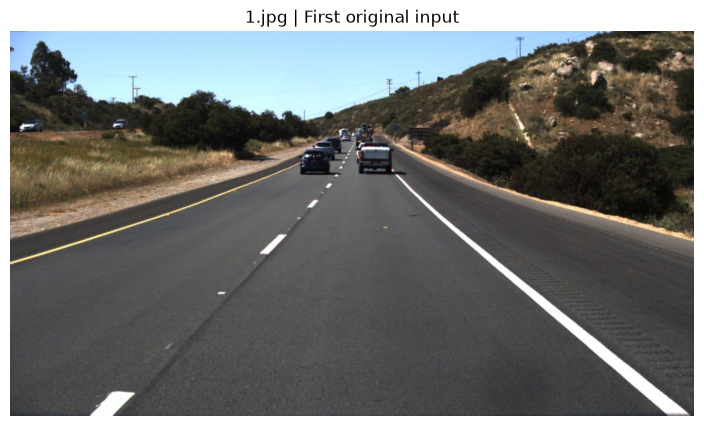

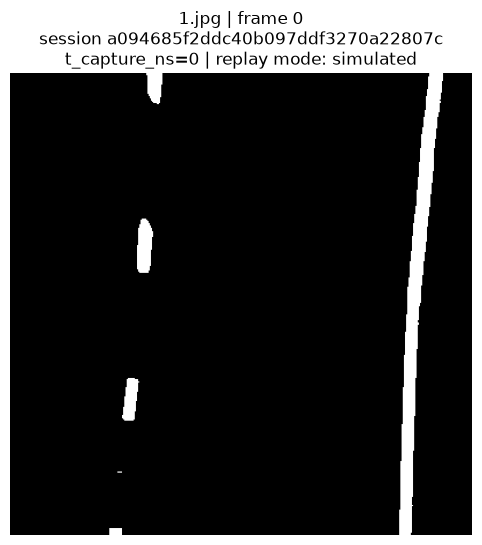

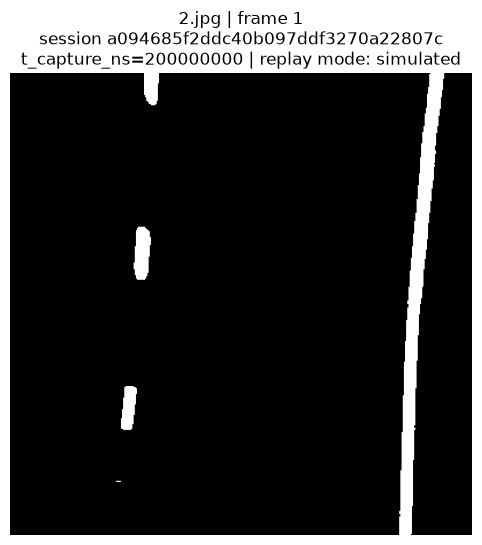

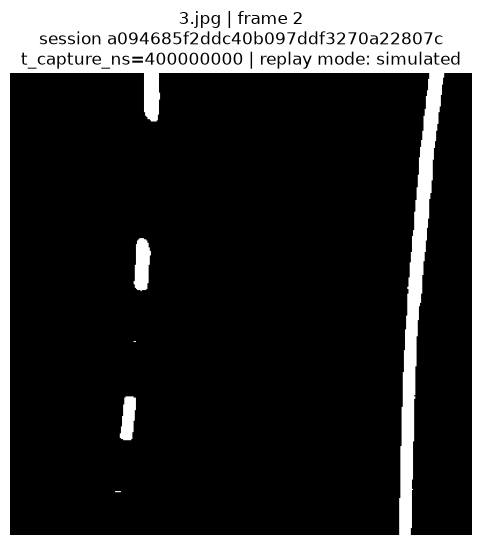

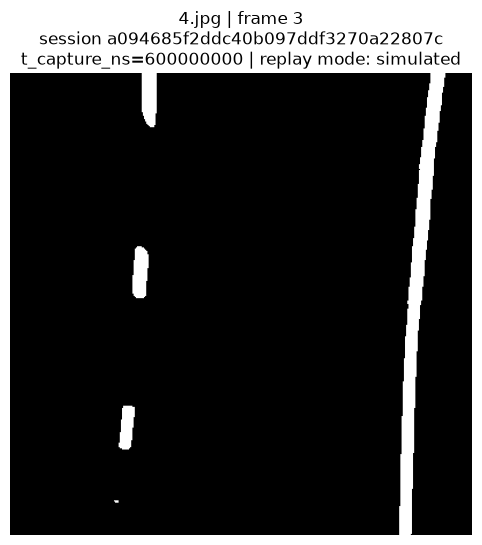

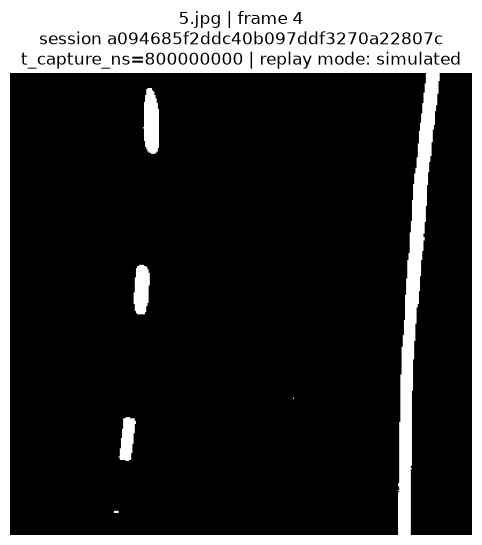

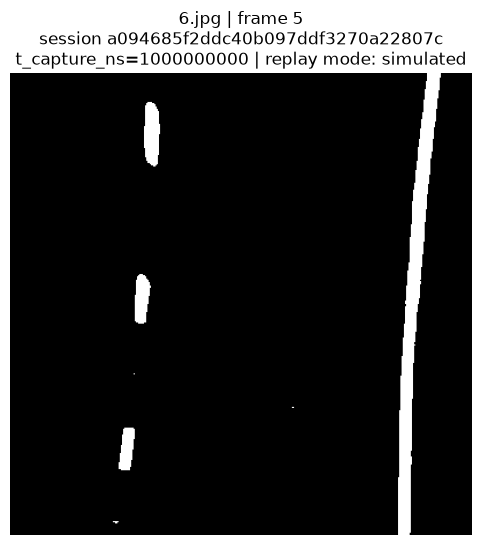

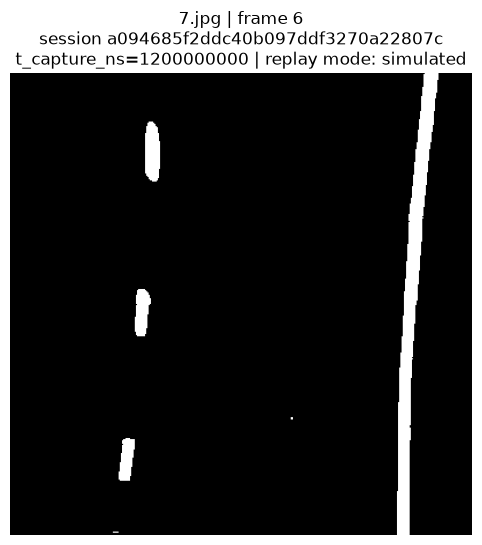

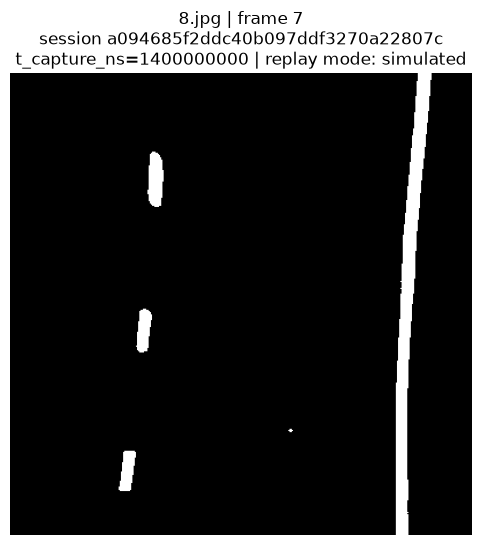

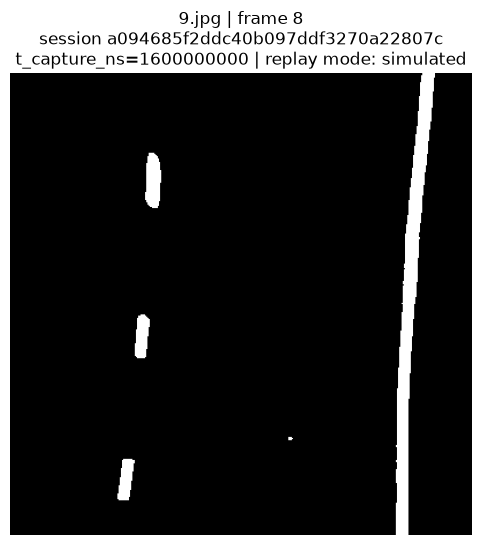

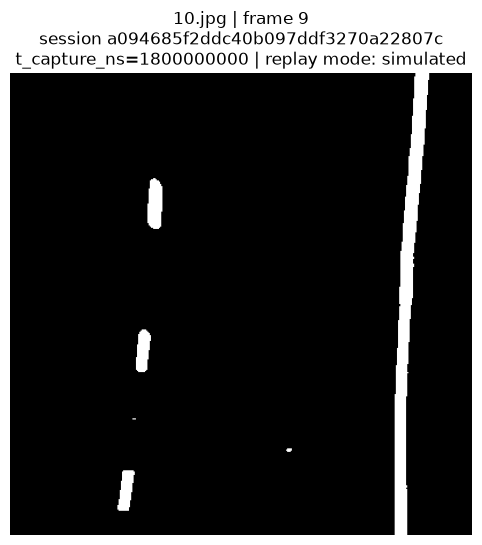

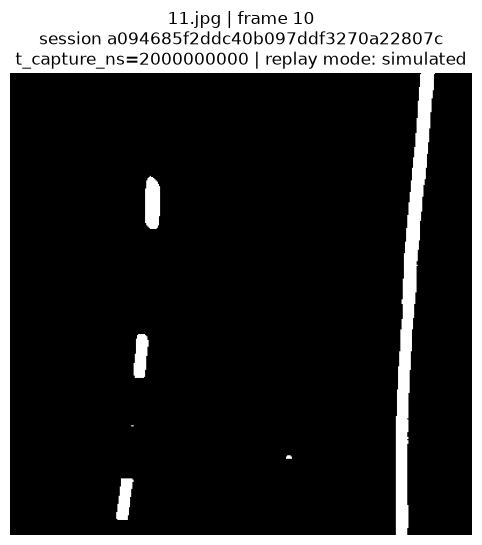

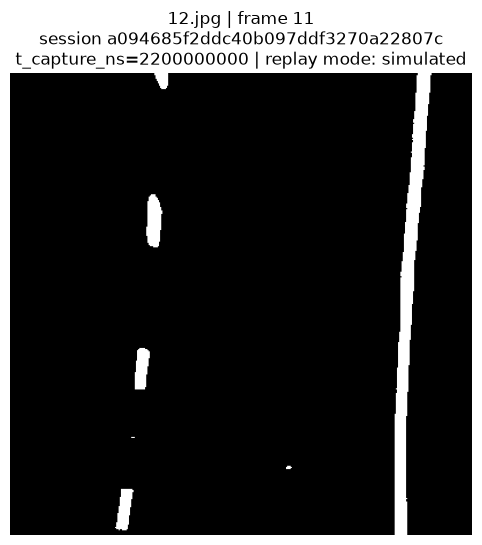

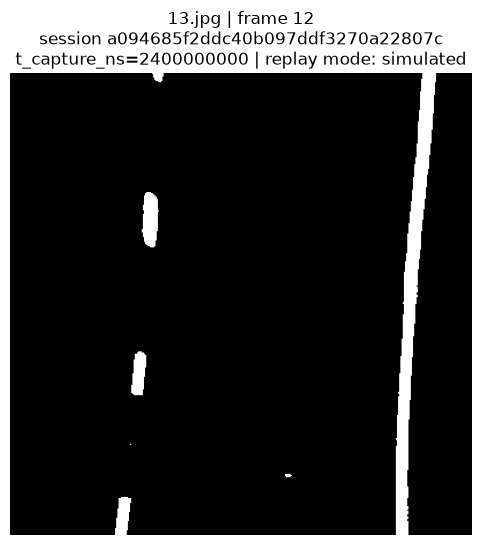

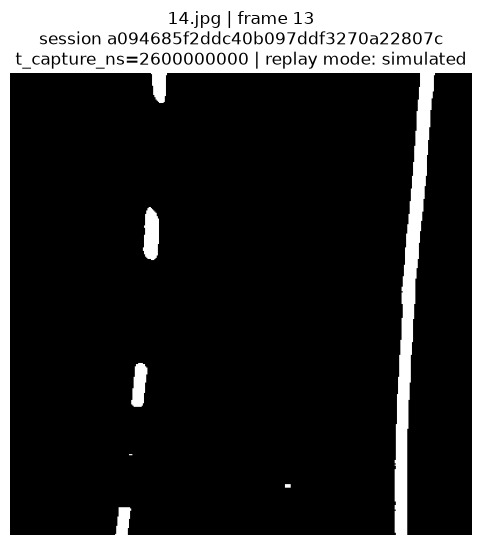

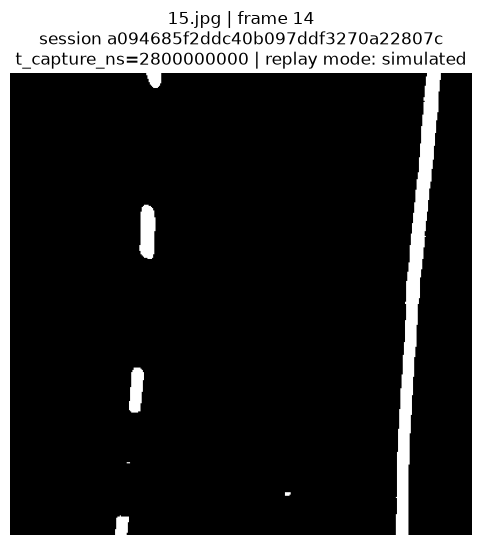

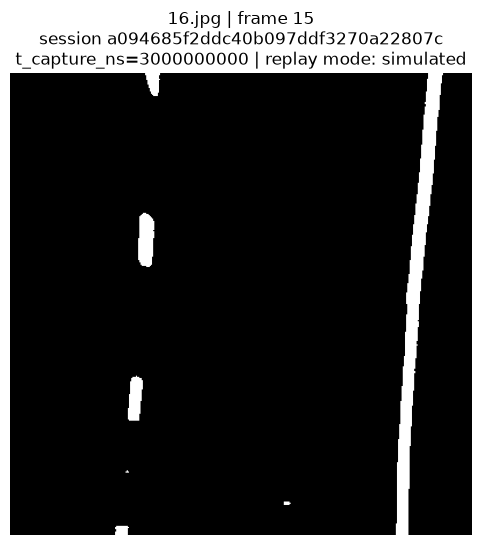

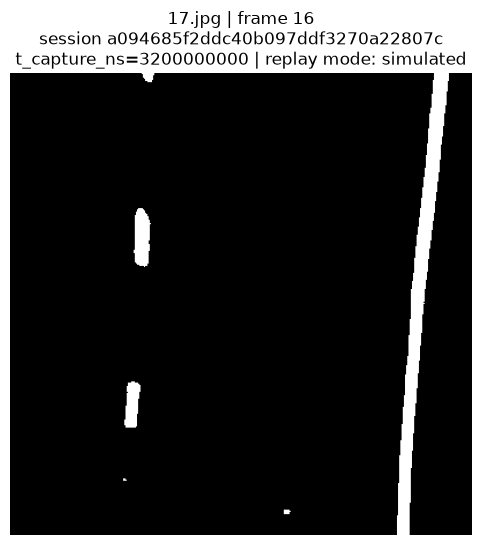

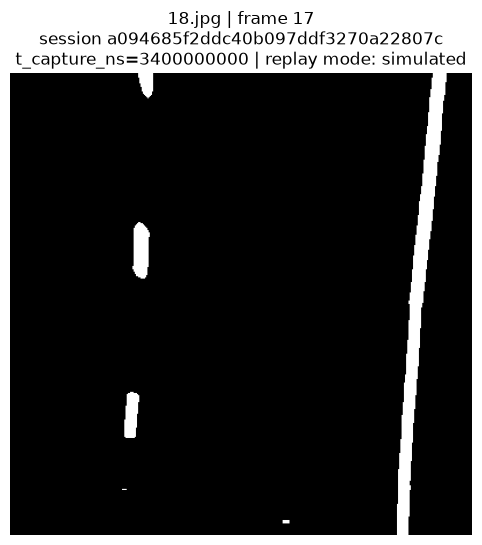

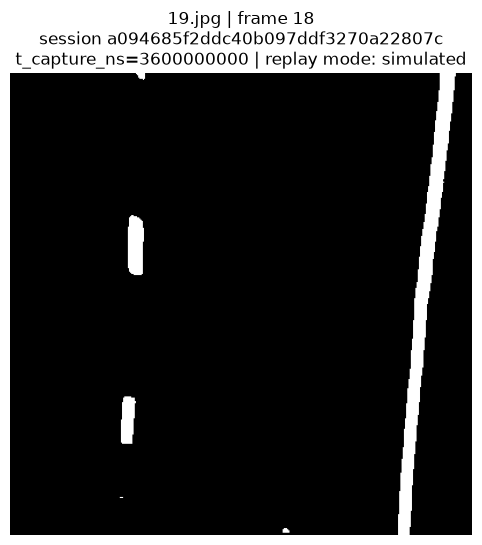

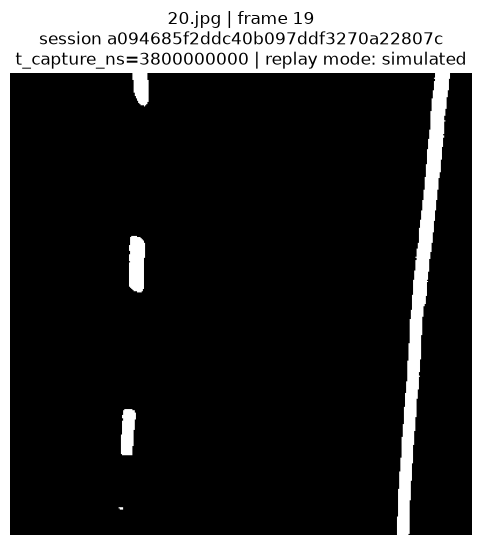

Processed: 20
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 0, 't_capture_ns': 0, 'replay_mode': 'simulated', 'capture_delta_ns': None}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 1, 't_capture_ns': 200000000, 'replay_mode': 'simulated', 'capture_delta_ns': 200000000}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 2, 't_capture_ns': 400000000, 'replay_mode': 'simulated', 'capture_delta_ns': 200000000}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 3, 't_capture_ns': 600000000, 'replay_mode': 'simulated', 'capture_delta_ns': 200000000}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 4, 't_capture_ns': 800000000, 'replay_mode': 'simulated', 'capture_delta_ns': 200000000}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 5, 't_capture_ns': 1000000000, 'replay_mode': 'simulated', 'capture_delta_ns': 200000000}
{'session_id': 'a094685f2ddc40b097ddf3270a22807c', 'frame_id': 6, 't_capture_ns': 1200

In [5]:
processor = PreprocessingMixin()
ordering = FramePacketOrder()
timing = LatencyStatistics()
recent_metadata = deque(maxlen=20)
latest_result = None
previous_session = previous_capture = None
processed = 0
packets = iter_replay_packets(
    replay_path(TEST_IMAGE_DIRECTORY), mode=REPLAY_MODE, assumed_fps=ASSUMED_FPS,
    metadata_path=replay_path(RECORDED_METADATA_PATH), session_id=REPLAY_SESSION_ID,
    max_frames=MAX_FRAMES)
for packet in packets:
    packet = ordering.accept(packet)
    packet, original_input, adapted_input = adapt_notebook_packet(packet)
    if processed == 0:
        if original_input is None:
            from src.algorithms.LaneDetection.utils.img_codec import ImgCodecMixin
            original_input = ImgCodecMixin()._decode_b64_jpg_to_bgr(packet['image_b64'])
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.imshow(cv2.cvtColor(original_input, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{packet.get('image_name', 'frame')} | First original input")
        ax.axis('off')
        plt.show()
    result = preprocess_frame_packet(packet, processor, expected_frame_shape=((TEST_TARGET_HEIGHT, TEST_TARGET_WIDTH, 3) if USE_IMAGE_ADAPTATION else EXPECTED_FRAME_SHAPE))
    timing.add(replay_timing_sample(result))
    capture_delta_ns = (result['t_capture_ns'] - previous_capture
                        if result['session_id'] == previous_session else None)
    previous_session, previous_capture = result['session_id'], result['t_capture_ns']
    recent_metadata.append(dict(session_id=result['session_id'], frame_id=result['frame_id'],
                                t_capture_ns=result['t_capture_ns'], replay_mode=REPLAY_MODE,
                                capture_delta_ns=capture_delta_ns))
    latest_result = result
    if processed < DISPLAY_LIMIT:
        fig, ax = plt.subplots(figsize=(6, 6))
        ax.imshow(result['binary_bev'], cmap='gray', vmin=0, vmax=1)
        ax.set_title(f"{packet.get('image_name', 'frame')} | frame {result['frame_id']}\n"
                     f"session {result['session_id']}\n"
                     f"t_capture_ns={result['t_capture_ns']} | replay mode: {REPLAY_MODE}")
        ax.axis('off')
        plt.show()
    processed += 1
print('Processed:', processed)
for row in recent_metadata:
    print(row)

## Host timing diagnostics

Median and p95 are reported after at least five samples. These are measurements on the current development computer, **not Raspberry Pi camera latency**. Replay reports host queue/decode/preprocessing durations only: recorded/simulated capture clocks are never subtracted from this computer's monotonic clock. Live results additionally support capture-to-publish, publish-to-receive and estimated frame-age metrics.

In [5]:
summary = timing.summary()
print('Host monotonic clock resolution (ns):', summary['host_clock_resolution_ns'])
print('Zero measured durations can mean work is below this clock resolution.')
if not summary['ready']:
    print(f"Insufficient timing samples: {summary['samples']}/{summary['required_samples']}")
else:
    print('Replay host processing timings (milliseconds), not Raspberry Pi performance:')
    for metric, values in summary['metrics_ms'].items():
        print(f"{metric}: median={values['median']:.3f}, p95={values['p95']:.3f}, n={values['samples']}")

Host monotonic clock resolution (ns): 15625000
Zero measured durations can mean work is below this clock resolution.
Replay host processing timings (milliseconds), not Raspberry Pi performance:
preprocessing: median=0.000, p95=16.750, n=20
processing_including_decode: median=0.000, p95=16.750, n=20
wait_before_processing: median=0.000, p95=0.000, n=20


## Recorded metadata format

Use a JSONL record per line, a JSON array of records, or a JSON object containing a `frames` list. Example record:

```json
{"image_path":"frame0001.jpg","session_id":"original-pi-session","frame_id":125,"t_capture_ns":583204510000,"t_publish_ns":583205000000}
```

Image paths may be absolute or relative to IMAGE_DIRECTORY (or the manifest directory). Records require only identity/capture metadata and an image path; no replay-specific packet field is required. Timing mode belongs to this notebook, not production. The notebook passes only current-host stage timestamps to latency summaries, excluding recorded/simulated capture and original publish clocks. Recorded timestamps and identities are not rewritten, and malformed/out-of-order rows raise a clear error. For missing original metadata, use simulated mode instead of inventing recorded times.

A live session UUID changes after camera restart; frame counters may then restart at zero. Recorded camera timestamps from another boot/machine are a separate clock domain. A complete recorder and MCU/IMU synchronization are outside this phase.

## Next phase — Row-Scan Candidate Extraction (not implemented)

Future candidate extraction/tracking starts from `latest_result['binary_bev']` and its original `session_id`, `frame_id`, `t_capture_ns`. No row scan, lane fits, tracking, sensor fusion or control is implemented in Phase 0.2.